# Calibration 5 — Biên độ ±7% của HOSE: CAcF và GARCH có kiểm duyệt

**Vì sao cần.** EDA (Phát hiện 4) cho thấy biên ±7% chặn đuôi lỗ/lãi: phiên chạm sàn/trần chỉ cho biết lợi suất **không nhỏ hơn / không lớn hơn** ngưỡng
(dữ liệu bị **kiểm duyệt**, censored), còn lợi suất tiềm ẩn có thể lớn hơn. Processing (Phát hiện 2) mô phỏng việc chặn bằng cách cắt phân vị 1,5% trên dữ liệu i.i.d.
(`CT.simulate_scm(setting="censored")`) — mô phỏng này **không** có ngưỡng tuyệt đối, biến động theo thời gian $\sigma_t$, và cờ chạm biên, nên chưa phản ánh đúng đặc điểm thật.

**Bài báo dùng.** Xu, Shu & Chen (2024), *Tail Risk Dynamics under Price-Limited Constraint: A Censored Autoregressive Conditional Fréchet Model*, Entropy 26:555,
doi:10.3390/e26070555. Họ mô hình cực đại chéo $Q_t = \max_i(-r_{it})$ bằng Fréchet có tham số động $(\sigma_t, \alpha_t)$ và likelihood kiểm duyệt (CAcF). Notebook này:

1. **(A) Mô hình của bài báo:** áp đúng CAcF cho $Q_t$ của 60 mã HOSE (mô-đun `src/price_limit.py`, import là `PL`).
2. **(B) Mở rộng của đồ án, không phải mô hình trong bài báo:** GARCH(1,1)–$t$ có kiểm duyệt cho từng mã, mượn cơ chế kiểm duyệt (3), nguyên tắc likelihood (5) và cách bù cú sốc chạm biên ở Remark 3 của bài báo.
3. Kiểm tra bằng **mô phỏng có ngưỡng tuyệt đối + biến động chung** xem bù kiểm duyệt có cải thiện SID của EASE không.
4. Chạy lại **EASE trên dữ liệu thật** với phần dư đã bù kiểm duyệt (điền nhiều lần, multiple imputation) và xem thứ tự có đổi không.

Ghi chú đơn vị: các tham số của CAcF được ước lượng trên $Q\times 100$ (đơn vị %), nên $\mu,\sigma_t$ trong bảng tính bằng %; $\alpha_t$ không có đơn vị.

## 0. Thiết lập

In [1]:
import os, sys, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
# worker của joblib/loky là tiến trình mới: cần PYTHONPATH để import được price_limit, eda_utils...
os.environ["PYTHONPATH"] = os.pathsep.join([str(ROOT / "src"), os.environ.get("PYTHONPATH", "")]).rstrip(os.pathsep)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import tail_preprocessing as TP
import calibration as C
import price_limit as PL
from scipy import stats
from joblib import Parallel, delayed

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình png → report/figure/calibration, pdf → report/pdf/calibration, bảng → report/table/calibration
RECOMPUTE = False                           # True: chạy lại mô phỏng ở mục 3 (mặc định đọc bộ nhớ đệm CSV)
warnings.filterwarnings("ignore", category=RuntimeWarning)
T_START = time.time()

con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
r.index = pd.to_datetime(r.index)
raw_flags = con.execute("SELECT time, symbol, hit_floor, hit_ceiling FROM v_analysis").df()
raw_flags["time"] = pd.to_datetime(raw_flags["time"])


def pivot_flag(col):
    d = raw_flags.assign(v=raw_flags[col].astype(float))
    w = d.pivot_table(index="time", columns="symbol", values="v", aggfunc="max")
    return w.reindex(index=r.index, columns=SYMBOLS).fillna(0.0).astype(bool)


FL, CE = pivot_flag("hit_floor"), pivot_flag("hit_ceiling")
n, P = len(r), len(SYMBOLS)
HIT = pd.DataFrame({"floor_pct": FL.mean() * 100, "ceil_pct": CE.mean() * 100})
HIT["hit_pct"] = HIT.floor_pct + HIT.ceil_pct
print(f"n = {n} phiên ({r.index[0]:%d/%m/%Y} – {r.index[-1]:%d/%m/%Y}), {P} mã; "
      f"tỷ lệ phiên chạm biên: trung bình {HIT.hit_pct.mean():.2f}%, thấp nhất {HIT.hit_pct.idxmin()} {HIT.hit_pct.min():.2f}%, "
      f"cao nhất {HIT.hit_pct.idxmax()} {HIT.hit_pct.max():.2f}%")

n = 2103 phiên (05/06/2018 – 25/11/2026), 60 mã; tỷ lệ phiên chạm biên: trung bình 4.12%, thấp nhất VNM 0.57%, cao nhất DIG 9.27%


## 1. $Q_t$ và CAcF cho cực đại chéo của lợi suất âm

**Tính gì:** $Q_t=\max_i(-r_{it})$ (mã lỗ nặng nhất trong phiên), cờ kiểm duyệt $D_t=1$ khi **có ít nhất một mã** chạm sàn trong phiên (khi đó $Q_t$ chỉ là cận dưới của mức lỗ tiềm ẩn lớn nhất, $M_t=Q_t$),
và mô hình Fréchet có tham số động (CAcF) của Xu–Shu–Chen.

**Công thức.**
$$Q^*_t=\mu+\sigma_t Y_t^{-1/\alpha_t},\quad Y_t\sim\text{Exp}(1),\qquad
\log\sigma_t=\beta_0+\beta_1\log\sigma_{t-1}+(\beta_2+\beta_2^{*}D_{t-1})\,G_1(Q_{t-1}),$$
$$\log\alpha_t=\gamma_0+\gamma_1\log\alpha_{t-1}-(\gamma_2+\gamma_2^{*}D_{t-1})\,G_2(Q_{t-1}),$$
$G(z)=z$ (L), $\mathrm{sgn}(z)z^2$ (S), $-e^{-cz}$ (E). Log-likelihood kiểm duyệt: phiên $D_t=1$ đóng góp $\log\{1-\exp(-\sigma_t^{\alpha_t}(M_t-\mu)^{-\alpha_t})\}$ (xác suất vượt ngưỡng),
phiên $D_t=0$ đóng góp log mật độ Fréchet. **AcF** = cùng mô hình nhưng coi mọi $D_t=0$ (bỏ qua kiểm duyệt, bỏ $\beta_2^*,\gamma_2^*$).
Xác suất một bước tới bị chặn $\hat P_t=1-\exp(-\hat\sigma_t^{\hat\alpha_t}(M-\hat\mu)^{-\hat\alpha_t})$ với $M$ = trung vị các ngưỡng quan sát ở phiên $D_t=1$ trong mẫu;
**Lưu ý (proxy):** $\hat P_t=P(Q^*_t>M)$ dùng **một** ngưỡng cố định $M$, còn $D_t=1$ nghĩa là *có mã nào đó chạm sàn riêng của nó* (ngưỡng thật đổi theo từng phiên/mã vì bước giá), nên $\hat P_t$ chỉ là xấp xỉ của xác suất $D_t=1$; có kiểm tra độ nhạy theo $M$ bên dưới. Kiểm định tỉ số hợp lý (LR) cho $\beta_2^*=\gamma_2^*=0$ dùng `fit_cacf(..., compensation=False)`.

$\mathrm{EVaR}_\tau=\mu+\frac{\sigma_t}{1-\tau}\gamma\!\left(1-\tfrac1{\alpha_t},-\log\tau\right)$ (không kiểm duyệt; $\gamma$ là hàm gamma bất toàn dưới không chuẩn hoá), EVaR của biến kiểm duyệt $\min(Q^*,M)$ tính bằng tích phân số trên phân vị.

**Các bước:** (1) dựng $Q_t,D_t$ từ 60 mã; (2) khớp CAcF-L/S/E và AcF-L trên mẫu đến 31/12/2024; (3) lọc tiếp tham số cố định cho 2025 trở đi (`PL.predict_cacf`) và so
Brier score của $\hat P_t$ với $D_t$ thực, đối chứng bằng tần suất $D_t=1$ trong mẫu; (4) vẽ động học và EVaR 95%.

In [2]:
qt = PL.qt_series(r, FL)
SPLIT = pd.Timestamp("2024-12-31")
qi, qo = qt[qt.index <= SPLIT], qt[qt.index > SPLIT]
M0 = float(qi.loc[qi.D == 1, "Q"].median())          # ngưỡng đại diện (đơn vị gốc) để tính P̂_t, EVaR kiểm duyệt
print(f"Q_t: {len(qt)} phiên; D_t=1 chiếm {qt.D.mean():.1%} (trong mẫu {qi.D.mean():.1%}, ngoài mẫu {qo.D.mean():.1%}); "
      f"trong mẫu {len(qi)} phiên, ngoài mẫu {len(qo)} phiên ({qo.index[0]:%d/%m/%Y} – {qo.index[-1]:%d/%m/%Y})")
print(f"Q_t (%): min {qt.Q.min()*100:.2f}, trung vị {qt.Q.median()*100:.2f}, max {qt.Q.max()*100:.2f}; ngưỡng M (trung vị Q khi D=1) = {M0*100:.3f}%")
print(f"Q_t nhỏ nhất vào {qt.Q.idxmin():%d/%m/%Y}; số phiên Q_t < 0: {(qt.Q < 0).sum()}; D_t=1 khi bất kỳ mã chạm sàn; số phiên n_floor ≥ 1: {(qt.n_floor >= 1).sum()}")
print("Mã đạt cực đại nhiều nhất:", qt.argmax.value_counts().head(5).to_dict())

t0 = time.time()
fits = {"CAcF-L": PL.fit_cacf(qi.Q, qi.D, qi.M, kind="L"),
        "CAcF-S": PL.fit_cacf(qi.Q, qi.D, qi.M, kind="S"),
        "CAcF-E": PL.fit_cacf(qi.Q, qi.D, qi.M, kind="E"),
        "AcF-L": PL.fit_cacf(qi.Q, qi.D, qi.M, kind="L", censored=False)}
print(f"khớp 4 mô hình: {time.time() - t0:.1f}s")
rows = []
for name, f in fits.items():
    p = f.params
    rows.append({"mô hình": name, "μ (%)": f.mu * 100, "μ − min(Q) (%)": f.mu * 100 - qi.Q.min() * 100,
                 "β1": p["beta1"], "γ1": p["gamma1"], "β2": p["beta2"], "γ2": p["gamma2"],
                 "β2*": p.get("beta2s", np.nan), "γ2*": p.get("gamma2s", np.nan),
                 "β3": p.get("beta3", np.nan), "γ3": p.get("gamma3", np.nan),
                 "loglik": f.loglik, "AIC": f.aic, "BIC": f.bic,
                 "α_t trung vị": f.alpha_t.median(), "α_t min": f.alpha_t.min(), "α_t max": f.alpha_t.max(),
                 "σ_t trung vị (%)": f.sigma_t.median() * 100, "hội tụ": f.converged})
cacf_params = pd.DataFrame(rows).set_index("mô hình")
U.save_table(cacf_params, "05_cacf_params", FOLDER)
cacf_params.T

Q_t: 2103 phiên; D_t=1 chiếm 18.2% (trong mẫu 17.8%, ngoài mẫu 19.6%); trong mẫu 1633 phiên, ngoài mẫu 470 phiên (02/01/2025 – 25/11/2026)
Q_t (%): min -6.32, trung vị 3.69, max 8.41; ngưỡng M (trung vị Q khi D=1) = 7.223%
Q_t nhỏ nhất vào 10/04/2025; số phiên Q_t < 0: 9; D_t=1 khi bất kỳ mã chạm sàn; số phiên n_floor ≥ 1: 382
Mã đạt cực đại nhiều nhất: {'HAG': 93, 'NVL': 75, 'ANV': 70, 'FRT': 66, 'CTD': 66}


khớp 4 mô hình: 17.3s


mô hình,CAcF-L,CAcF-S,CAcF-E,AcF-L
μ (%),-6.012,-5.967,-5.549,-59.695
μ − min(Q) (%),-4.733,-4.688,-4.270,-58.416
β1,0.777,0.769,0.859,0.785
γ1,0.740,0.741,0.768,0.735
β2,0.015,0.002,0.107,0.002
γ2,0.032,0.004,0.266,0.050
β2*,0.001,-0.000,-2.304,NaN
γ2*,0.038,0.005,-5.000,NaN
β3,NaN,NaN,0.596,NaN
γ3,NaN,NaN,0.389,NaN


In [3]:
# Ngoài mẫu: lọc tiếp tham số cố định; P̂_t với ngưỡng M0 cho mọi phiên
preds = {k: PL.predict_cacf(f, qo.Q, qo.D, M0) for k, f in fits.items()}
p0 = float(qi.D.mean())
brier = lambda p, d: float(np.mean((np.asarray(p, float) - np.asarray(d, float)) ** 2))
rows = []
for k, f in fits.items():
    p_in = PL.censored_probability(f, M0)
    rows.append({"mô hình": k, "Brier trong mẫu": brier(p_in, qi.D), "Brier ngoài mẫu": brier(preds[k].p_censored, qo.D),
                 "P̂ trung bình ngoài mẫu": preds[k].p_censored.mean(), "P̂ min": preds[k].p_censored.min(),
                 "P̂ max": preds[k].p_censored.max()})
rows.append({"mô hình": "Hằng số (tần suất D trong mẫu)", "Brier trong mẫu": brier(np.full(len(qi), p0), qi.D),
             "Brier ngoài mẫu": brier(np.full(len(qo), p0), qo.D), "P̂ trung bình ngoài mẫu": p0,
             "P̂ min": p0, "P̂ max": p0})
oos = pd.DataFrame(rows).set_index("mô hình")
b_ref = oos.loc["Hằng số (tần suất D trong mẫu)", "Brier ngoài mẫu"]
oos["Brier skill (so với hằng số)"] = 1 - oos["Brier ngoài mẫu"] / b_ref
oos["D thực tế ngoài mẫu"] = qo.D.mean()
oos["AUC ngoài mẫu"] = [stats.mannwhitneyu(preds[k].p_censored[qo.D == 1], preds[k].p_censored[qo.D == 0]).statistic
                        / ((qo.D == 1).sum() * (qo.D == 0).sum()) if k in preds else np.nan for k in oos.index]
U.save_table(oos, "05_cacf_oos", FOLDER)
print(f"Ngoài mẫu: {int(qo.D.sum())} phiên D=1 / {len(qo)}; tần suất tĩnh trong mẫu p0 = {p0:.3f}")
oos

Ngoài mẫu: 92 phiên D=1 / 470; tần suất tĩnh trong mẫu p0 = 0.178


,Brier trong mẫu,Brier ngoài mẫu,P̂ trung bình ngoài mẫu,P̂ min,P̂ max,Brier skill (so với hằng số),D thực tế ngoài mẫu,AUC ngoài mẫu
mô hình,,,,,,,,
CAcF-L,0.116,0.134,0.184,0.024,0.555,0.148,0.196,0.766
CAcF-S,0.116,0.135,0.184,0.030,0.556,0.143,0.196,0.762
CAcF-E,0.117,0.139,0.170,0.000,0.549,0.117,0.196,0.730
AcF-L,0.130,0.148,0.104,0.011,0.341,0.060,0.196,0.769
Hằng số (tần suất D trong mẫu),0.146,0.158,0.178,0.178,0.178,0.000,0.196,NaN


,phân vị của Q khi D=1,M0 (%),mô hình,Brier ngoài mẫu,P̂ trung bình ngoài mẫu,AUC ngoài mẫu,Brier hằng số
0,0.250,7.166,CAcF-L,0.134,0.187,0.766,0.158
1,0.250,7.166,AcF-L,0.148,0.107,0.769,0.158
2,0.500,7.223,CAcF-L,0.134,0.184,0.766,0.158
3,0.500,7.223,AcF-L,0.148,0.104,0.769,0.158
4,0.750,7.258,CAcF-L,0.135,0.182,0.766,0.158
5,0.750,7.258,AcF-L,0.149,0.103,0.769,0.158


LR = 34.051, p = 0.0000 (χ² 2 bậc tự do)


D:\2026.1\Đồ án II\src\eda_utils.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


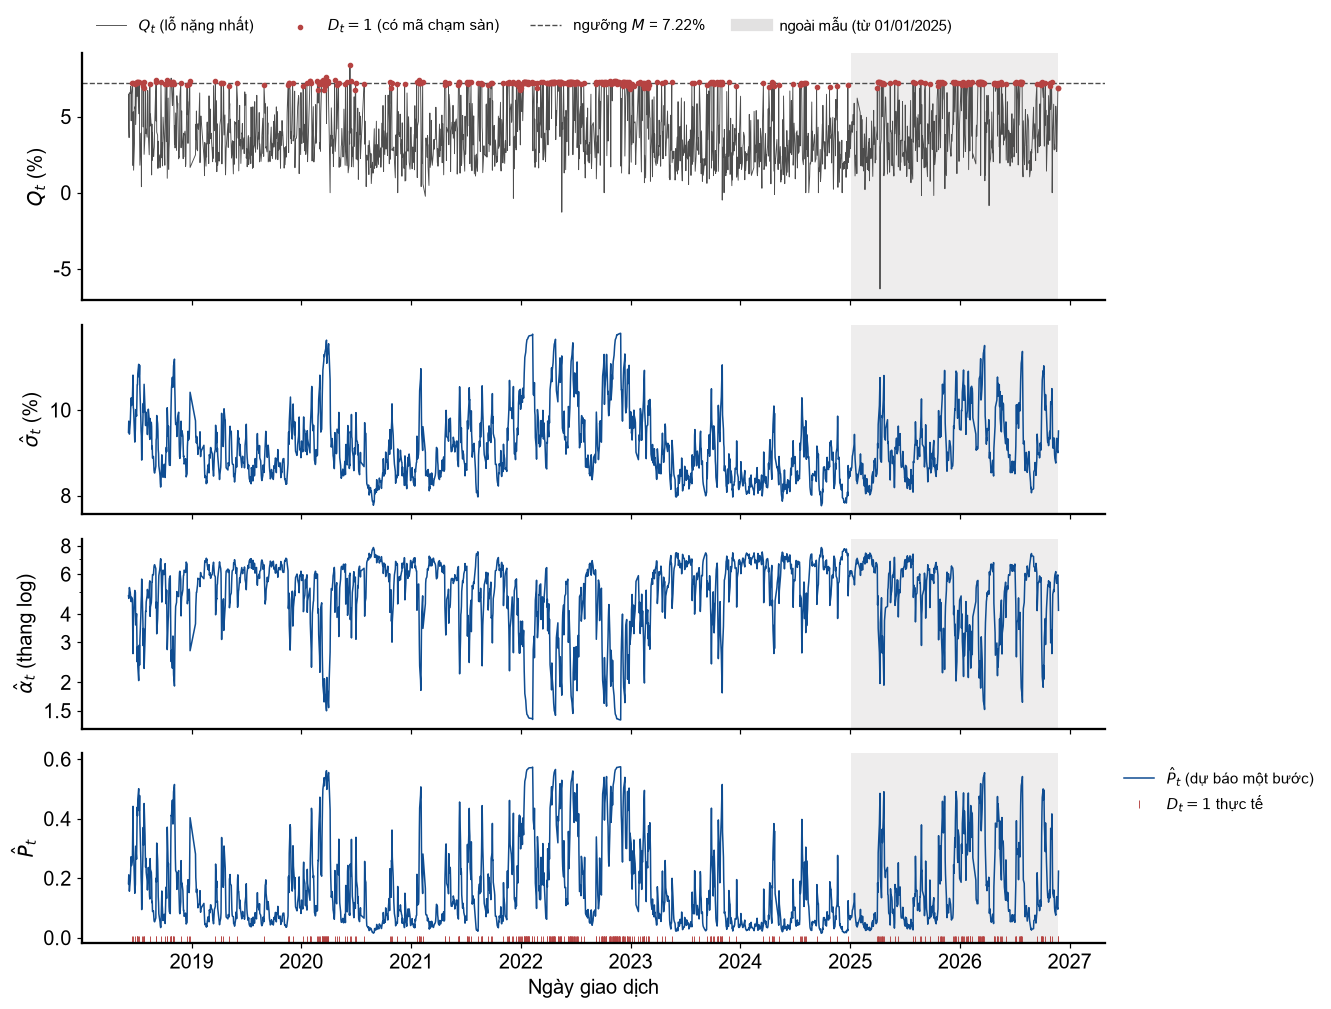

σ̂_t (%): trung vị 9.03, [min, max] = [7.76, 11.79]; α̂_t: trung vị 5.6, [1.4, 7.9]; P̂_t: trung bình 0.170, [0.015, 0.574]
corr(σ̂_t, P̂_t) = 0.979; corr(α̂_t, P̂_t) = -0.978


In [4]:
# Độ nhạy theo M0 và kiểm định LR cho β2* = γ2* = 0
rows = []
for qq in (0.25, 0.5, 0.75):
    Mq = float(qi.loc[qi.D == 1, "Q"].quantile(qq))
    for k in ("CAcF-L", "AcF-L"):
        pq = PL.predict_cacf(fits[k], qo.Q, qo.D, Mq).p_censored
        auc = stats.mannwhitneyu(pq[qo.D == 1], pq[qo.D == 0]).statistic / ((qo.D == 1).sum() * (qo.D == 0).sum())
        rows.append({"phân vị của Q khi D=1": qq, "M0 (%)": Mq * 100, "mô hình": k, "Brier ngoài mẫu": brier(pq, qo.D),
                     "P̂ trung bình ngoài mẫu": pq.mean(), "AUC ngoài mẫu": auc})
sens = pd.DataFrame(rows)
sens["Brier hằng số"] = b_ref
U.save_table(sens.set_index(["phân vị của Q khi D=1", "mô hình"]), "05_cacf_m0_sensitivity", FOLDER)
display(sens)

f_red = PL.fit_cacf(qi.Q, qi.D, qi.M, kind="L", compensation=False)
LR = 2 * (fits["CAcF-L"].loglik - f_red.loglik)
lr = pd.DataFrame([{"loglik đầy đủ (CAcF-L)": fits["CAcF-L"].loglik, "loglik thu gọn (β2*=γ2*=0)": f_red.loglik, "LR": LR,
                    "bậc tự do": 2, "p-value": stats.chi2.sf(LR, 2), "hội tụ đầy đủ": bool(fits["CAcF-L"].converged),
                    "hội tụ thu gọn": bool(f_red.converged), "AIC đầy đủ": fits["CAcF-L"].aic, "AIC thu gọn": f_red.aic}])
U.save_table(lr, "05_cacf_lr", FOLDER)
print(f"LR = {LR:.3f}, p = {stats.chi2.sf(LR, 2):.4f} (χ² 2 bậc tự do)")
lr.T

# Hình 1: động học CAcF-L (4 hàng, chung trục thời gian)
f = fits["CAcF-L"]; pr = preds["CAcF-L"]
sig = pd.concat([f.sigma_t, pr.sigma]) * 100
alp = pd.concat([f.alpha_t, pr.alpha])
pt = pd.concat([PL.censored_probability(f, M0), pr.p_censored])
d1 = qt.D == 1

fig, ax = plt.subplots(4, 1, figsize=(12, 10.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1, 1], "hspace": 0.12})
for a in ax:
    a.axvspan(qo.index[0], qt.index[-1], color=PAL["neutral"], alpha=0.35, lw=0)
ax[0].plot(qt.index, qt.Q * 100, color=PAL["gray_dark"], lw=0.6, label=r"$Q_t$ (lỗ nặng nhất)")
ax[0].scatter(qt.index[d1], qt.Q[d1] * 100, s=7, color=PAL["red_strong"], zorder=3, label=r"$D_t=1$ (có mã chạm sàn)")
ax[0].axhline(M0 * 100, color=PAL["gray_dark"], ls="--", lw=0.9, label=f"ngưỡng $M$ = {M0 * 100:.2f}%")
ax[0].set_ylabel(r"$Q_t$ (%)")
ax[1].plot(sig.index, sig, color=PAL["blue_main"], lw=1.0); ax[1].set_ylabel(r"$\hat\sigma_t$ (%)")
ax[2].plot(alp.index, alp, color=PAL["blue_main"], lw=1.0); ax[2].set_yscale("log"); ax[2].set_yticks([1.5, 2, 3, 4, 6, 8]); ax[2].yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g")); ax[2].yaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax[2].set_ylabel(r"$\hat\alpha_t$ (thang log)")
ax[3].plot(pt.index, pt, color=PAL["blue_main"], lw=1.0, label=r"$\hat P_t$ (dự báo một bước)")
ax[3].plot(qt.index[d1], np.full(d1.sum(), -0.012 * max(pt.max(), 0.05)), "|", color=PAL["red_strong"], ms=5, mew=0.6, label=r"$D_t=1$ thực tế")
ax[3].set_ylabel(r"$\hat P_t$"); ax[3].set_xlabel("Ngày giao dịch")
ax[3].set_ylim(-0.03 * pt.max(), pt.max() * 1.08)
ax[0].plot([], [], color=PAL["neutral"], lw=8, alpha=0.6, label="ngoài mẫu (từ 01/01/2025)")
h0, l0 = ax[0].get_legend_handles_labels()
ax[0].legend(h0, l0, loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=4, frameon=False, fontsize=10)
h3, l3 = ax[3].get_legend_handles_labels()
ax[3].legend(h3, l3, loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False, fontsize=10)
U.finalize_figure(fig, "05_cacf_dynamics", folder=FOLDER); plt.show()
print(f"σ̂_t (%): trung vị {sig.median():.2f}, [min, max] = [{sig.min():.2f}, {sig.max():.2f}]; "
      f"α̂_t: trung vị {alp.median():.1f}, [{alp.min():.1f}, {alp.max():.1f}]; P̂_t: trung bình {pt.mean():.3f}, [{pt.min():.3f}, {pt.max():.3f}]")
print(f"corr(σ̂_t, P̂_t) = {np.corrcoef(sig, pt)[0, 1]:.3f}; corr(α̂_t, P̂_t) = {np.corrcoef(alp, pt)[0, 1]:.3f}")

In [5]:
# Kiểm tra giới hạn của mô hình: μ chạm cận dưới? α̂_t có "đuôi Fréchet nặng" như SSE50 của bài báo (α khoảng 2–12)?
chk = []
for k, ft in fits.items():
    gap = ft.mu * 100 - qi.Q.min() * 100
    chk.append({"mô hình": k, "min(Q) (%)": qi.Q.min() * 100, "μ (%)": ft.mu * 100, "min(Q) − μ (%)": -gap,
                "α_t p5": ft.alpha_t.quantile(.05), "α_t trung vị": ft.alpha_t.median(), "α_t p95": ft.alpha_t.quantile(.95),
                "α_t ≤ 12": (ft.alpha_t <= 12).mean()})
display(pd.DataFrame(chk).set_index("mô hình"))
st_acf = PL.fit_static_censored_frechet(qi.Q.to_numpy() * 100, np.zeros(len(qi), dtype=int), qi.Q.to_numpy() * 100)
sdQ = float(qi.Q.std() * 100)
print(f"AcF: cận dưới của μ trong tham số hoá = min(Q) − 30·sd(Q) = {qi.Q.min() * 100 - 30 * sdQ:.2f}%; μ của Fréchet tĩnh (điểm khởi đầu) = {st_acf['mu']:.2f}%, α tĩnh = {st_acf['alpha']:.1f}; "
      f"μ của AcF-L sau tối ưu = {fits['AcF-L'].mu * 100:.2f}%")
print("Cờ hội tụ:", {k: bool(v.converged) for k, v in fits.items()})

,min(Q) (%),μ (%),min(Q) − μ (%),α_t p5,α_t trung vị,α_t p95,α_t ≤ 12
mô hình,,,,,,,
CAcF-L,-1.279,-6.012,4.733,2.027,5.640,7.172,1.000
CAcF-S,-1.279,-5.967,4.688,2.013,5.592,6.947,1.000
CAcF-E,-1.279,-5.549,4.270,1.911,5.320,6.968,1.000
AcF-L,-1.279,-59.695,58.416,24.823,40.993,54.165,0.000


AcF: cận dưới của μ trong tham số hoá = min(Q) − 30·sd(Q) = -62.25%; μ của Fréchet tĩnh (điểm khởi đầu) = -62.23%, α tĩnh = 37.9; μ của AcF-L sau tối ưu = -59.70%
Cờ hội tụ: {'CAcF-L': True, 'CAcF-S': True, 'CAcF-E': True, 'AcF-L': True}


D:\2026.1\Đồ án II\src\eda_utils.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


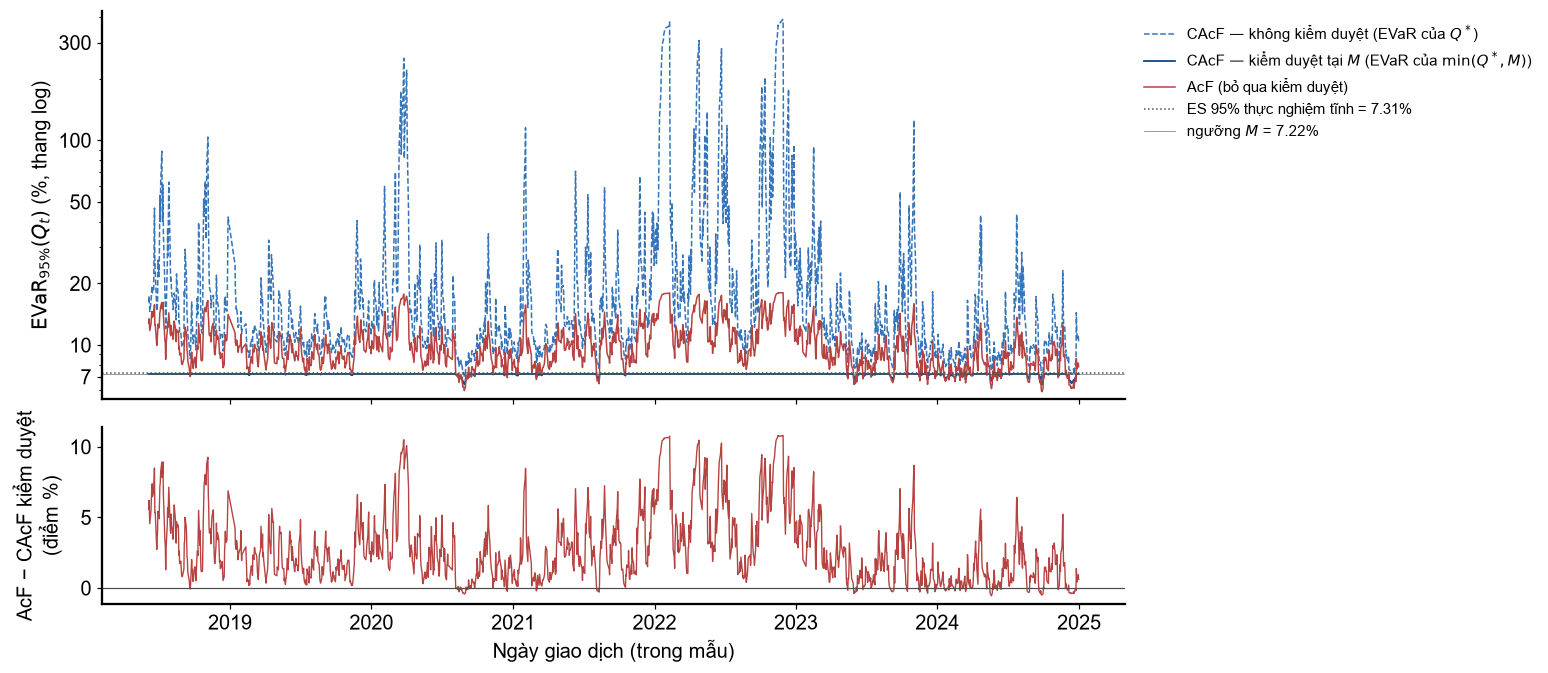

EVaR 95% (%), trong mẫu:


,mean,min,50%,max
CAcF không kiểm duyệt,26.801,6.981,12.626,389.244
CAcF kiểm duyệt,7.196,6.405,7.223,7.223
AcF,10.021,5.916,9.363,18.031


Q_t trong mẫu: max 8.41%, tỷ lệ phiên Q > M0 = 8.9%; ES thực nghiệm 95% của Q (trong mẫu) = 7.31%; EVaR kiểm duyệt bị chặn bởi M0 theo cấu trúc
AcF − CAcF kiểm duyệt: trung bình 2.825 điểm %, AcF cao hơn ở 93.1% phiên; EVaR kiểm duyệt ≤ không kiểm duyệt ở 100.0% phiên; NaN: 0 / 0


In [6]:
# Hình 2: EVaR 95% — CAcF không kiểm duyệt vs CAcF kiểm duyệt vs AcF (mẫu trong), cùng ngưỡng M0
TAU = 0.95
fL, fA = fits["CAcF-L"], fits["AcF-L"]
ev_unc = PL.evar(fL, TAU) * 100
ev_cen = PL.evar_censored(fL, TAU, M0) * 100
ev_acf = PL.evar(fA, TAU) * 100
es_emp = float(qi.Q[qi.Q >= qi.Q.quantile(TAU)].mean() * 100)          # ES thực nghiệm tĩnh của Q_t trong mẫu
gap = ev_acf - ev_cen

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.1})
a1.plot(ev_unc.index, ev_unc, color=PAL["blue_secondary"], lw=1.0, ls="--", label="CAcF — không kiểm duyệt (EVaR của $Q^*$)")
a1.plot(ev_cen.index, ev_cen, color=PAL["blue_main"], lw=1.2, label="CAcF — kiểm duyệt tại $M$ (EVaR của $\\min(Q^*,M)$)")
a1.plot(ev_acf.index, ev_acf, color=PAL["red_strong"], lw=1.0, label="AcF (bỏ qua kiểm duyệt)")
a1.axhline(es_emp, color=PAL["gray_dark"], ls=":", lw=1.0, label=f"ES 95% thực nghiệm tĩnh = {es_emp:.2f}%")
a1.axhline(M0 * 100, color=PAL["gray_dark"], ls="-", lw=0.6, alpha=0.6, label=f"ngưỡng $M$ = {M0 * 100:.2f}%")
a1.set_ylabel(r"$\mathrm{EVaR}_{95\%}(Q_t)$ (%, thang log)")
lo_, hi_ = np.nanmin([ev_unc.min(), ev_cen.min(), ev_acf.min(), es_emp]), np.nanmax([ev_unc.max(), ev_cen.max(), ev_acf.max(), M0 * 100])
a1.set_yscale("log"); a1.set_ylim(lo_ * 0.92, hi_ * 1.1)
a1.set_yticks([7, 10, 20, 50, 100, 300]); a1.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g")); a1.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
a1.legend(loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False, fontsize=10)
a2.plot(gap.index, gap, color=PAL["red_strong"], lw=0.9)
a2.axhline(0, color=PAL["gray_dark"], lw=0.8)
a2.set_ylabel("AcF − CAcF kiểm duyệt\n(điểm %)"); a2.set_xlabel("Ngày giao dịch (trong mẫu)")
U.finalize_figure(fig, "05_cacf_evar", folder=FOLDER); plt.show()
evt = pd.DataFrame({"CAcF không kiểm duyệt": ev_unc, "CAcF kiểm duyệt": ev_cen, "AcF": ev_acf}).describe().T[["mean", "min", "50%", "max"]]
print(f"EVaR 95% (%), trong mẫu:"); display(evt)
print(f"Q_t trong mẫu: max {qi.Q.max() * 100:.2f}%, tỷ lệ phiên Q > M0 = {(qi.Q > M0).mean():.1%}; ES thực nghiệm 95% của Q (trong mẫu) = {es_emp:.2f}%; EVaR kiểm duyệt bị chặn bởi M0 theo cấu trúc")
print(f"AcF − CAcF kiểm duyệt: trung bình {gap.mean():.3f} điểm %, AcF cao hơn ở {(gap > 0).mean():.1%} phiên; "
      f"EVaR kiểm duyệt ≤ không kiểm duyệt ở {(ev_cen <= ev_unc + 1e-12).mean():.1%} phiên; NaN: {int(ev_unc.isna().sum())} / {int(ev_acf.isna().sum())}")

### Phân tích

- **Dữ liệu.** $Q_t$ có 2103 phiên, $D_t=1$ ở 18,2% phiên (trong mẫu 17,8%, ngoài mẫu 19,6%; 382 phiên có ít nhất một mã chạm sàn). Ngưỡng đại diện $M$ = trung vị $Q_t$ khi $D_t=1$ = 7,223%. Có 9 phiên $Q_t<0$ (cả 60 mã cùng tăng); sâu nhất là 10/04/2025 với $Q_t=-6{,}32\%$ — điểm ngoại lai nằm ở phần ngoài mẫu.
- **Tham số CAcF-L** (đơn vị %): $\hat\mu=-6{,}01$, $\hat\beta_1=0{,}777$, $\hat\gamma_1=0{,}740$ (động học dai dẳng); $\hat\beta_2^*=0{,}001\approx0$ nhưng $\hat\gamma_2^*=0{,}038>\hat\gamma_2=0{,}032$: điểm ước lượng cho thấy ngay sau phiên bị chặn $\alpha_t$ giảm mạnh gấp $(0{,}032+0{,}038)/0{,}032\approx2{,}2$ lần phiên thường, còn $\sigma_t$ hầu như không phản ứng thêm. Kiểm định tỉ số hợp lý cho $\beta_2^*=\gamma_2^*=0$ (log-lik đầy đủ −2987,3 so với thu gọn −3004,4; AIC 5992,7 so với 6022,7): **LR = 34,05, p = 4,0·10⁻⁸** (χ² 2 bậc tự do), nên phần bù kiểm duyệt có ý nghĩa thống kê (kiểm định chung cho hai tham số, không tách riêng được từng tham số). Log-lik: L −2987,3; S −2992,7; E −2983,4 (AIC 5992,7 / 6003,4 / 5988,8). E hơn L 3,9 điểm AIC nhưng $\hat\beta_2^*=-2{,}30$, $\hat\gamma_2^*=-5{,}00$ (chạm cận dưới −5 của tham số hoá) nên không tin được; chọn **L** làm mô hình chính. Với tiêu chí KKT mới, cả bốn mô hình đều báo `hội tụ = True` (kể cả CAcF-S và CAcF-E, dù $\hat\gamma_2^*$ của E nằm đúng cận −5: KKT chỉ đòi gradient không chỉ ra ngoài miền). AcF-L có log-lik −3305,2 (AIC 6624,4) nhưng đó là likelihood **không kiểm duyệt** (coi $Q$ bị chặn là mật độ), nên không so AIC trực tiếp với CAcF.
- **Giới hạn quan trọng — không tái hiện được chẩn đoán "μ chạm cận, α 10–80" cho CAcF.** Trong lần chạy này, với CAcF-L/S/E thì $\hat\mu\approx-6{,}0\%$ cách $\min Q=-1{,}28\%$ khoảng 4,7 điểm % (không chạm cận) và $\hat\alpha_t$ trung vị 5,6 (khoảng 1,4–7,9; 100% phiên $\le12$), tức **nằm trong** vùng 2–12 của SSE50 trong bài báo. Chẩn đoán "μ ở cận dưới, α ≈ 21–62" chỉ đúng gần đúng với **AcF-L**: $\hat\mu$ trôi rất xa ($-59{,}7\%$) và $\hat\alpha_t$ trung vị 41,0 (21,5–62,2), tức dạng gần Gumbel. Cận dưới của tham số hoá ($\min Q-30\,\mathrm{sd}(Q)=-62{,}25\%$) bị chạm bởi **điểm khởi đầu** (Fréchet tĩnh không kiểm duyệt: $\hat\mu=-62{,}23\%$, $\hat\alpha=37{,}9$) chứ không phải nghiệm cuối của AcF-L (cách cận 2,5 điểm %). Bỏ kiểm duyệt vẫn đẩy Fréchet về dạng gần Gumbel. Dù vậy, $Q_t$ (cực đại 60 mã) có trung vị 3,69% — phần lớn là *thân* chứ không phải đuôi — và $\hat\mu\approx-6\%$ là rất xa, nên nên diễn giải **động học** ($\hat\sigma_t$, $\hat P_t$, $\hat\gamma_2^*$), không diễn giải trực tiếp mức $\mu$ hay $\alpha$ như chỉ số đuôi.
- **Động học.** $\hat\sigma_t$ trong 7,76–11,79%, $\hat\alpha_t$ trong 1,36–7,87, $\hat P_t$ trong 0,015–0,574. $\hat\sigma_t$ và $\hat\alpha_t$ gần như đối xứng nhau: tương quan với $\hat P_t$ lần lượt 0,979 và −0,978, tức mô hình thực chất chỉ có **một** nhân tố động (giai đoạn 2020, đầu 2022 và cuối 2022 có $\hat P_t$ cao nhất).
- **Dự báo ngoài mẫu** (470 phiên, 92 phiên $D=1$; tần suất tĩnh trong mẫu $p_0=0{,}178$): Brier CAcF-L **0,134**, CAcF-S 0,135, CAcF-E 0,139, AcF-L 0,148, hằng số 0,158 ⇒ Brier skill 14,8% / 14,3% / 11,7% / 6,0%. Về **xếp hạng** hai mô hình ngang nhau (AUC 0,766 so với 0,769 của AcF); lợi thế của CAcF là **hiệu chuẩn**: $\bar{\hat P}$ = 0,184 so với tần suất thực 0,196, trong khi AcF chỉ 0,104 (đánh giá thấp gần một nửa). $\hat P_t$ chỉ là **proxy**: nó dùng một ngưỡng cố định $M$ còn $D_t=1$ nghĩa là có mã nào đó chạm sàn riêng của nó (ngưỡng thật đổi theo phiên/mã). Độ nhạy theo $M$ (phân vị 25/50/75 của $Q$ khi $D=1$ = 7,166 / 7,223 / 7,258%): Brier ngoài mẫu CAcF-L 0,134 / 0,134 / 0,135 và AcF-L 0,148 / 0,148 / 0,149; $\bar{\hat P}$ 0,187 / 0,184 / 0,182 và 0,107 / 0,104 / 0,103; AUC không đổi (0,766 và 0,769) — kết luận không phụ thuộc vào cách chọn $M$, và khả năng **xếp hạng** của hai mô hình là như nhau.
- **EVaR 95% (trong mẫu).** EVaR không kiểm duyệt của CAcF-L trung bình 26,8% (trung vị 12,6%, cực đại 389%) — không dùng được vì $\hat\alpha_t$ có lúc ≈ 1,4 làm kỳ vọng gần như không tồn tại. EVaR kiểm duyệt bị chặn bởi $M$ (= 7,223%, trung vị các ngưỡng quan sát khi $D=1$) **theo cấu trúc**, nên việc nó trung bình 7,196% và luôn $\le M$ không phải là kết quả thực nghiệm. $M$ cũng không phải mức lỗ tối đa quan sát được ($Q_t$ trong mẫu tối đa 8,41%; 8,9% số phiên có $Q_t>M$ vì ngưỡng từng mã khác nhau), nên không so 'công bằng' được với ES thực nghiệm tĩnh 95% của $Q_t$ (7,31%). AcF cho trung bình 10,02% (trung vị 9,36%, cực đại 18,0%): thấp hơn EVaR không kiểm duyệt ở mức trung vị (9,4 so với 12,6) nhưng cao hơn EVaR kiểm duyệt trung bình 2,83 điểm % (ở 93,1% phiên). AcF và CAcF không kiểm duyệt trả lời hai câu hỏi khác nhau (rủi ro tiềm ẩn so với rủi ro dưới biên), nên chỉ nên nói AcF 'đánh giá thấp' hay 'phóng đại' rủi ro khi nêu rõ đại lượng được so sánh.


## 2. GARCH(1,1)–$t$ có kiểm duyệt cho từng mã

**Tính gì:** ba biến thể cho mỗi mã trong 60 mã: **thường** (coi lợi suất đã chặn là quan sát đầy đủ, tương đương `arch`/`TP.garch_standardize`), **kiểm duyệt**
(phiên chạm biên đóng góp xác suất, không phải mật độ), và **kiểm duyệt + δ** (thêm cú sốc chạm biên vào phương sai).

**Công thức.** $r^*_t=\mu+\sigma_t\varepsilon_t$, $\varepsilon_t\sim t_\nu$ chuẩn hoá (phương sai 1); $r_t=\mathrm{clip}(r^*_t,-c_t,c_t)$;
$$\sigma_t^2=\omega+a(r_{t-1}-\mu)^2+b\,\sigma_{t-1}^2+\delta^{-}F_{t-1}+\delta^{+}C_{t-1},$$
$F,C$ = cờ chạm sàn/trần. Log-likelihood: phiên thường $\log f_\varepsilon$; phiên sàn $\log F_\varepsilon((c_t-\mu)/\sigma_t)$; phiên trần $\log\{1-F_\varepsilon((c_t-\mu)/\sigma_t)\}$.
Phần dư quan sát $z_t=(r_t-\mu)/\sigma_t$ (ở phiên bị chặn bằng ngưỡng chuẩn hoá). BIC $=-2\ell+q\ln n$, $q=5$ (không δ) hoặc 7 (có δ).
Chỉ so BIC giữa hai biến thể **kiểm duyệt** (cùng loại likelihood); likelihood của biến thể thường là mật độ nên không so được trực tiếp với likelihood kiểm duyệt.

**Các bước:** khớp song song 60 mã × 3 biến thể (`joblib`); lập bảng $\nu$, $a+b$, $\delta^-$ (chia cho $\mathrm{Var}(r)$ để không còn đơn vị), BIC; lưu $z$ quan sát của biến thể kiểm duyệt + δ.

In [7]:
VARIANTS = {"thuong": dict(censored=False, limit_terms=False),
            "kd": dict(censored=True, limit_terms=False),
            "kd_delta": dict(censored=True, limit_terms=True)}
NPAR = {"thuong": 5, "kd": 5, "kd_delta": 7}


def fit_stock(sym):
    return sym, {v: PL.fit_censored_garch(r[sym], FL[sym], CE[sym], **kw) for v, kw in VARIANTS.items()}


t0 = time.time()
res = dict(Parallel(n_jobs=4)(delayed(fit_stock)(s) for s in SYMBOLS))
print(f"GARCH 60 mã × 3 biến thể: {time.time() - t0:.0f}s")

rows = []
for s in SYMBOLS:
    row = {"mã": s, "ngành": U.SECTOR[s], "chạm sàn (%)": HIT.floor_pct[s], "chạm trần (%)": HIT.ceil_pct[s], "chạm biên (%)": HIT.hit_pct[s]}
    for v in VARIANTS:
        p = res[s][v]["params"]
        row.update({f"ν {v}": p["nu"], f"a+b {v}": p["persistence"], f"loglik {v}": p["loglik"],
                    f"BIC {v}": -2 * p["loglik"] + NPAR[v] * np.log(n), f"hội tụ {v}": p["converged"]})
    pd_ = res[s]["kd_delta"]["params"]
    vr = float(r[s].var())
    row.update({"δ⁻/Var(r)": pd_["delta_floor"] / vr, "δ⁺/Var(r)": pd_["delta_ceil"] / vr})
    row["BIC thắng (kd vs kd+δ)"] = "kd+δ" if row["BIC kd_delta"] < row["BIC kd"] else "kd"
    row["ΔBIC (kd − kd+δ)"] = row["BIC kd"] - row["BIC kd_delta"]
    row["Δν (thường − kd+δ)"] = row["ν thuong"] - row["ν kd_delta"]
    rows.append(row)
gt = pd.DataFrame(rows).set_index("mã")
U.save_table(gt, "05_censored_garch_params", FOLDER)

Z_obs = pd.DataFrame({s: res[s]["kd_delta"]["z_obs"] for s in SYMBOLS})
NU_KD = pd.Series({s: res[s]["kd_delta"]["params"]["nu"] for s in SYMBOLS})
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
Z_obs.to_parquet(ROOT / "data" / "processed" / "censored_garch_resid.parquet")
print("đã lưu data/processed/censored_garch_resid.parquet", Z_obs.shape)

nconv = {v: int(gt[f"hội tụ {v}"].sum()) for v in VARIANTS}
print("số mã hội tụ:", nconv)
print(f"kd+δ thắng BIC (so với kd): {(gt['BIC thắng (kd vs kd+δ)'] == 'kd+δ').sum()}/{P} mã")
for v in VARIANTS:
    print(f"{v:9s}: ν trung vị {gt[f'ν {v}'].median():6.2f} (min {gt[f'ν {v}'].min():.2f}, max {gt[f'ν {v}'].max():.1f}); "
          f"a+b trung vị {gt[f'a+b {v}'].median():.4f}, số mã a+b > 0,99: {(gt[f'a+b {v}'] > 0.99).sum()}, > 0,999: {(gt[f'a+b {v}'] > 0.999).sum()}")
print(f"ν giảm sau kiểm duyệt (Δν > 0): {(gt['Δν (thường − kd+δ)'] > 0).sum()}/{P} mã; Spearman(Δν, tỷ lệ chạm biên) = "
      f"{stats.spearmanr(gt['Δν (thường − kd+δ)'], gt['chạm biên (%)'])[0]:.3f}")
print("Δν lớn nhất:"); display(gt.nlargest(6, "Δν (thường − kd+δ)")[["ngành", "chạm biên (%)", "ν thuong", "ν kd", "ν kd_delta", "a+b thuong", "a+b kd_delta"]])
print(f"δ⁻/Var(r): trung vị {gt['δ⁻/Var(r)'].median():.3f}, δ⁻ > 0 ở {(gt['δ⁻/Var(r)'] > 0).sum()}/{P} mã; δ⁺/Var(r) trung vị {gt['δ⁺/Var(r)'].median():.3f}")

GARCH 60 mã × 3 biến thể: 21s
đã lưu data/processed/censored_garch_resid.parquet (2103, 60)
số mã hội tụ: {'thuong': 60, 'kd': 60, 'kd_delta': 60}
kd+δ thắng BIC (so với kd): 36/60 mã
thuong   : ν trung vị   4.31 (min 3.04, max 8.1); a+b trung vị 0.9951, số mã a+b > 0,99: 41, > 0,999: 23
kd       : ν trung vị   3.39 (min 2.91, max 4.3); a+b trung vị 0.9999, số mã a+b > 0,99: 57, > 0,999: 54
kd_delta : ν trung vị   2.98 (min 2.58, max 3.9); a+b trung vị 0.9999, số mã a+b > 0,99: 49, > 0,999: 48
ν giảm sau kiểm duyệt (Δν > 0): 60/60 mã; Spearman(Δν, tỷ lệ chạm biên) = 0.897
Δν lớn nhất:


,ngành,chạm biên (%),ν thuong,ν kd,ν kd_delta,a+b thuong,a+b kd_delta
mã,,,,,,,
DXG,Bất động sản,7.846,8.122,3.750,2.787,0.979,1.000
DIG,Bất động sản,9.272,7.363,4.337,2.984,0.997,1.000
TCH,Bất động sản,7.038,6.136,3.499,2.862,0.964,1.000
DGW,Tiêu dùng,7.038,6.028,3.606,2.761,0.990,1.000
PVD,Năng lượng,6.372,6.265,3.858,3.082,0.994,1.000
HCM,Chứng khoán,5.516,5.822,3.539,3.091,0.977,0.970


δ⁻/Var(r): trung vị 2.657, δ⁻ > 0 ở 60/60 mã; δ⁺/Var(r) trung vị 0.434


D:\2026.1\Đồ án II\src\eda_utils.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


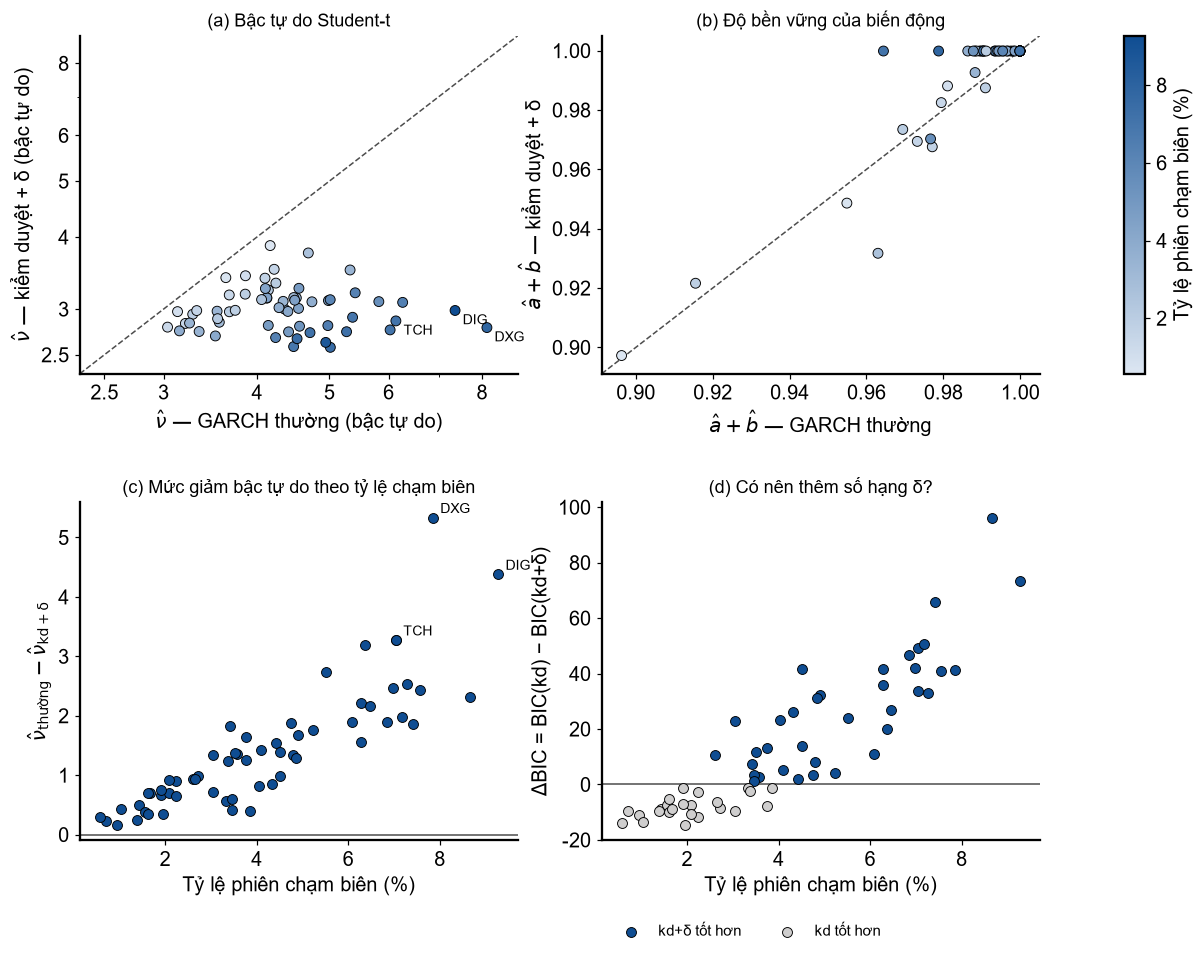

In [8]:
# Hình 3: so sánh GARCH thường vs kiểm duyệt (+δ)
hp = gt["chạm biên (%)"]
fig = plt.figure(figsize=(12.5, 9.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.05], wspace=0.28, hspace=0.38)
ax = np.array([[fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])], [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]])
cax = fig.add_subplot(gs[0, 2])
cm = mpl.colors.LinearSegmentedColormap.from_list("bl", ["#DCE6F2", PAL["blue_main"]])
norm = mpl.colors.Normalize(hp.min(), hp.max())
pk = dict(c=hp, cmap=cm, norm=norm, edgecolor="black", linewidth=0.6, s=42, zorder=3)

a = ax[0, 0]
sc = a.scatter(gt["ν thuong"], gt["ν kd_delta"], **pk)
lim = (min(gt["ν thuong"].min(), gt["ν kd_delta"].min()) * 0.9, max(gt["ν thuong"].max(), gt["ν kd_delta"].max()) * 1.1)
a.plot(lim, lim, color=PAL["gray_dark"], ls="--", lw=1); a.set_xlim(lim); a.set_ylim(lim)
a.set_xscale("log"); a.set_yscale("log")
for axis in (a.xaxis, a.yaxis):
    axis.set_major_locator(mpl.ticker.FixedLocator([2.5, 3, 4, 5, 6, 8])); axis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g")); axis.set_minor_formatter(mpl.ticker.NullFormatter())
a.set_xlabel(r"$\hat\nu$ — GARCH thường (bậc tự do)"); a.set_ylabel(r"$\hat\nu$ — kiểm duyệt + δ (bậc tự do)"); a.set_title("(a) Bậc tự do Student-t", fontsize=12)
for s in gt["Δν (thường − kd+δ)"].nlargest(3).index:
    a.annotate(s, (gt.loc[s, "ν thuong"], gt.loc[s, "ν kd_delta"]), xytext=(5, -9), textcoords="offset points", fontsize=9)

a = ax[0, 1]
a.scatter(gt["a+b thuong"], gt["a+b kd_delta"], **pk)
lo_, hi_ = min(gt["a+b thuong"].min(), gt["a+b kd_delta"].min()), max(gt["a+b thuong"].max(), gt["a+b kd_delta"].max())
pad = 0.05 * (hi_ - lo_)
a.plot([lo_ - pad, hi_ + pad], [lo_ - pad, hi_ + pad], color=PAL["gray_dark"], ls="--", lw=1)
a.set_xlim(lo_ - pad, hi_ + pad); a.set_ylim(lo_ - pad, hi_ + pad)
a.set_xlabel(r"$\hat a+\hat b$ — GARCH thường"); a.set_ylabel(r"$\hat a+\hat b$ — kiểm duyệt + δ"); a.set_title("(b) Độ bền vững của biến động", fontsize=12)
cb = fig.colorbar(sc, cax=cax); cb.set_label("Tỷ lệ phiên chạm biên (%)")

a = ax[1, 0]
a.scatter(hp, gt["Δν (thường − kd+δ)"], c=PAL["blue_main"], edgecolor="black", linewidth=0.6, s=42, zorder=3)
a.axhline(0, color=PAL["gray_dark"], lw=1)
for s in gt["Δν (thường − kd+δ)"].nlargest(3).index:
    a.annotate(s, (hp[s], gt.loc[s, "Δν (thường − kd+δ)"]), xytext=(5, 3), textcoords="offset points", fontsize=9)
a.set_xlabel("Tỷ lệ phiên chạm biên (%)"); a.set_ylabel(r"$\hat\nu_{\rm thường}-\hat\nu_{\rm kd+\delta}$"); a.set_title("(c) Mức giảm bậc tự do theo tỷ lệ chạm biên", fontsize=12)

a = ax[1, 1]
win = gt["ΔBIC (kd − kd+δ)"] > 0
a.scatter(hp[win], gt["ΔBIC (kd − kd+δ)"][win], c=PAL["blue_main"], edgecolor="black", linewidth=0.6, s=42, zorder=3, label="kd+δ tốt hơn")
a.scatter(hp[~win], gt["ΔBIC (kd − kd+δ)"][~win], c=PAL["neutral"], edgecolor="black", linewidth=0.6, s=42, zorder=3, label="kd tốt hơn")
a.axhline(0, color=PAL["gray_dark"], lw=1)
a.set_xlabel("Tỷ lệ phiên chạm biên (%)"); a.set_ylabel(r"$\Delta$BIC = BIC(kd) − BIC(kd+δ)"); a.set_title("(d) Có nên thêm số hạng δ?", fontsize=12)
a.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2, frameon=False, fontsize=10)
U.finalize_figure(fig, "05_garch_compare", folder=FOLDER); plt.show()

### Phân tích

- 60/60 mã hội tụ ở cả ba biến thể. $\hat\nu$ trung vị giảm từ **4,31** (thường) xuống **3,39** (kiểm duyệt) và **2,98** (kiểm duyệt + δ); giảm ở 60/60 mã, và mức giảm tăng mạnh theo tỷ lệ chạm biên (Spearman 0,897). Giảm nhiều nhất: DXG 8,12 → 2,79 (chạm biên 7,85%), DIG 7,36 → 2,98 (9,27%), TCH 6,14 → 2,86, DGW 6,03 → 2,76, PVD 6,27 → 3,08, HCM 5,82 → 3,09. (CTS có tỷ lệ chạm biên cao thứ hai nhưng không nằm trong nhóm giảm nhiều nhất.) Như vậy đuôi tiềm ẩn **dày hơn** nhiều so với ước lượng từ chuỗi bị chặn — phù hợp EDA Phát hiện 4 ($\hat\nu$ ở dữ liệu bị chặn không nên đọc như chỉ số đuôi).
- Thêm số hạng δ thắng BIC (so với kiểm duyệt thuần) ở **36/60** mã, hầu hết là các mã chạm biên khoảng ≥ 3–4% (panel d); với mã ít bị chặn, kiểm duyệt thuần đủ. $\hat\delta^-/\mathrm{Var}(r)$ dương ở 60/60 mã, trung vị 2,66 ($\hat\delta^+$: 0,43), tức sau phiên sàn phương sai điều kiện tăng thêm cỡ 2,7 lần phương sai vô điều kiện — hiệu ứng lớn, nên đọc cùng với giới hạn dưới đây.
- **Giới hạn: độ bền vững ≈ 1 (IGARCH-like).** Trung vị $\hat a+\hat b$ tăng từ 0,9951 (thường) lên 0,9999 (kiểm duyệt); số mã có $\hat a+\hat b>0{,}999$ từ 23 lên 54 (kiểm duyệt) và 48 (kiểm duyệt + δ). Hiện tượng này vẫn còn **kể cả khi không có δ**, nên không thể quy hết cho số hạng δ. Kết hợp $\hat\nu\approx3$ (mọi mã ở biến thể kiểm duyệt + δ có $\hat\nu\le3{,}9<4$, tức độ nhọn lý thuyết đã không hữu hạn), cho thấy GARCH(1,1)–t có thể bị sai đặc tả; phần dư kiểm duyệt dùng ở mục 4 vì vậy chưa phải "sự thật".

## 3. Mô phỏng: bù kiểm duyệt có giảm SID của EASE không?

**Tính gì:** SID (Structural Intervention Distance, đã chuẩn hoá về [0, 1] = tỷ lệ trong $p(p-1)=90$ cặp có thứ tự bị sai; thấp hơn tốt hơn) của EASE trên dữ liệu mô phỏng **có ngưỡng tuyệt đối** — khác mô phỏng cắt phân vị của Processing.

**Cơ chế sinh (`PL.simulate_limit_scm`):** SCM tuyến tính nhiễu $t(\alpha)$ với nhân tố ẩn (như `CT.simulate_scm(..., "hidden")`), nhân biến động chung $e^{h_t}$ ($h_t$ là AR(1) với hệ số 0,97),
rồi chặn theo ngưỡng tuyệt đối $L_j$ = phân vị $1-\text{hit\_rate}$ của $|R_j|$, $X=\mathrm{clip}(R,-L,L)$, kèm cờ sàn/trần.

**Bốn phương pháp** (EASE, $k=\lfloor n^{0{,}4}\rfloor$, trên phần dư GARCH–$t$): (1) *Không chặn* — chuỗi chưa bị chặn (đối chứng lý tưởng, không đạt được trên dữ liệu thật);
(2) *GARCH thường* — chuỗi bị chặn, bỏ qua kiểm duyệt (đối chứng); (3) *GARCH kiểm duyệt* — $z$ quan sát từ likelihood kiểm duyệt; (4) *kiểm duyệt + điền nhiều lần* — $m=10$ bản điền từ $t$ cắt cụt, gộp $\hat\Psi$ theo trung bình.

**Các bước:** lưới $\alpha\in\{1{,}5;3\}$ × hit rate $\in\{1\%;2{,}5\%;5\%\}$ × 40 lần lặp, $n=2000$, $p=10$; so cặp theo lần lặp (cùng dữ liệu) để có sai số chuẩn của hiệu SID.
Bộ nhớ đệm CSV: đặt `RECOMPUTE = True` ở ô thiết lập để chạy lại.

In [9]:
SIM_CSV = ROOT / "report" / "table" / "calibration" / "05_limit_sim.csv"
if RECOMPUTE or not SIM_CSV.exists():
    t0 = time.time()
    sim = PL.limit_simulation_study(reps=40, n=2000, p=10, alphas=(1.5, 3.0), hit_rates=(0.01, 0.025, 0.05),
                                    seed=2026, m_imp=10, n_jobs=4, limit_terms=False)
    U.save_table(sim, "05_limit_sim", FOLDER)
    print(f"mô phỏng: {time.time() - t0:.0f}s ({len(sim)} dòng)")
else:
    print("đọc bộ nhớ đệm", SIM_CSV.relative_to(ROOT))
sim = pd.read_csv(SIM_CSV, index_col=0, encoding="utf-8-sig")
METH = list(PL.SIM_METHODS)
agg = sim.groupby(["alpha", "hit_rate", "method"])["SID"].agg(["mean", "sem", "count"]).reset_index()
wide = sim.pivot_table(index=["alpha", "hit_rate", "rep"], columns="method", values="SID")
pair = pd.DataFrame({
    "thường − kd+MI": wide["GARCH thường"] - wide["Kiểm duyệt + điền nhiều lần"],
    "thường − kd (điểm)": wide["GARCH thường"] - wide["GARCH kiểm duyệt"],
    "kd+MI − không chặn": wide["Kiểm duyệt + điền nhiều lần"] - wide["Không chặn (GARCH)"]})
ps = pair.groupby(["alpha", "hit_rate"]).agg(["mean", "sem"])
ps.columns = [f"{a} ({b})" for a, b in ps.columns]
ps["P(kd+MI < thường)"] = (pair["thường − kd+MI"] > 0).groupby(["alpha", "hit_rate"]).mean()
ps["P(kd+MI = thường)"] = (pair["thường − kd+MI"] == 0).groupby(["alpha", "hit_rate"]).mean()
summary = agg.pivot_table(index=["alpha", "hit_rate"], columns="method", values="mean")[METH].join(ps)
U.save_table(summary, "05_limit_sim_summary", FOLDER)
print(f"{sim.groupby(['alpha', 'hit_rate', 'method']).size().iloc[0]} lần lặp mỗi ô; SID trung bình theo (α, hit rate):")
summary

đọc bộ nhớ đệm report\table\calibration\05_limit_sim.csv
40 lần lặp mỗi ô; SID trung bình theo (α, hit rate):


Không chặn (GARCH)  GARCH thường  GARCH kiểm duyệt  \
alpha hit_rate                                                       
1.500 0.010                  0.004         0.003             0.004   
      0.025                  0.005         0.021             0.019   
      0.050                  0.016         0.042             0.054   
3.000 0.010                  0.118         0.120             0.119   
      0.025                  0.088         0.093             0.094   
      0.050                  0.103         0.127             0.146   

                Kiểm duyệt + điền nhiều lần  thường − kd+MI (mean)  \
alpha hit_rate                                                       
1.500 0.010                           0.003                  0.000   
      0.025                           0.010                  0.011   
      0.050                           0.027                  0.014   
3.000 0.010                           0.117                  0.003   
      0.025                           0.101                 -0.008   
      0.050                           0.143                 -0.015   

                thường − kd+MI (sem)  thường − kd (điểm) (mean)  \
alpha hit_rate                                                    
1.500 0.010                    0.003                     -0.001   
      0.025                    0.006                      0.003   
      0.050                    0.012                     -0.012   
3.000 0.010                    0.007                      0.001   
      0.025                    0.013                     -0.001   
      0.050                    0.010                     -0.019   

                thường − kd (điểm) (sem)  kd+MI − không chặn (mean)  \
alpha hit_rate                                                        
1.500 0.010                        0.002                     -0.001   
      0.025                        0.003                      0.005   
      0.050                        0.021                      0.012   
3.000 0.010                        0.001                     -0.001   
      0.025                        0.005                      0.013   
      0.050                        0.007                      0.039   

                kd+MI − không chặn (sem)  P(kd+MI < thường)  P(kd+MI = thường)  
alpha hit_rate                                                                  
1.500 0.010                        0.004              0.025              0.950  
      0.025                        0.004              0.150              0.825  
      0.050                        0.009              0.275              0.650  
3.000 0.010                        0.006              0.100              0.825  
      0.025                        0.012              0.225              0.600  
      0.050                        0.011              0.225              0.400

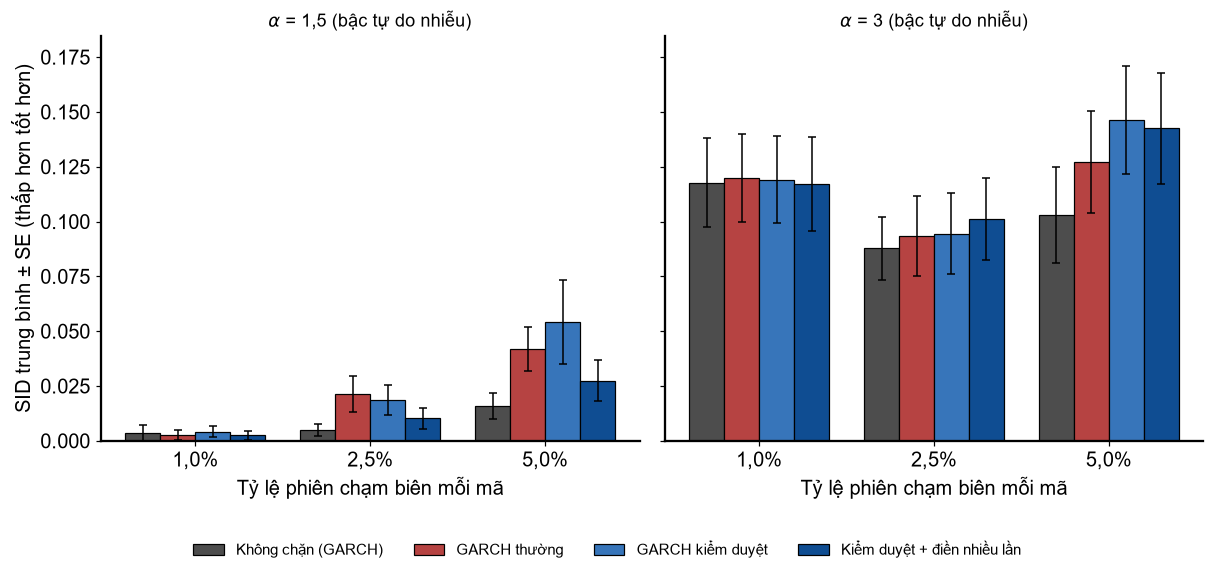

SID đã chuẩn hoá về [0, 1] (CT.sid, normalize=True): 0,011 ≈ 1 trên 90 cặp (tổ tiên → hậu duệ) có thứ tự bị sai


In [10]:
# Hình 4: SID ± SE theo phương pháp, nhóm theo hit rate, mỗi α một panel
mcol = {"Không chặn (GARCH)": PAL["gray_dark"], "GARCH thường": PAL["red_strong"],
        "GARCH kiểm duyệt": PAL["blue_secondary"], "Kiểm duyệt + điền nhiều lần": PAL["blue_main"]}
alphas_ = sorted(sim.alpha.unique()); hits_ = sorted(sim.hit_rate.unique())
fig, axes = plt.subplots(1, len(alphas_), figsize=(5.6 * len(alphas_), 4.8), sharey=True)
w = 0.2; x0 = np.arange(len(hits_))
top = (agg["mean"] + agg["sem"]).max()
for ax_, al in zip(np.atleast_1d(axes), alphas_):
    for j, m in enumerate(METH):
        d = agg[(agg.alpha == al) & (agg.method == m)].set_index("hit_rate").reindex(hits_)
        ax_.bar(x0 + (j - 1.5) * w, d["mean"], w, yerr=d["sem"], capsize=2.5, color=mcol[m], edgecolor="black", linewidth=0.8,
                error_kw=dict(elinewidth=1.0, ecolor="black"), label=m)
    ax_.set_xticks(x0, [f"{h:.1%}".replace(".", ",") for h in hits_])
    ax_.set_xlabel("Tỷ lệ phiên chạm biên mỗi mã"); ax_.set_title(rf"$\alpha$ = {al:g} (bậc tự do nhiễu)".replace(".", ","), fontsize=12)
    ax_.set_ylim(0, top * 1.08)
np.atleast_1d(axes)[0].set_ylabel("SID trung bình ± SE (thấp hơn tốt hơn)")
h_, l_ = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.1), fontsize=10)
U.finalize_figure(fig, "05_limit_sim", folder=FOLDER); plt.show()
print("SID đã chuẩn hoá về [0, 1] (CT.sid, normalize=True): 0,011 ≈ 1 trên 90 cặp (tổ tiên → hậu duệ) có thứ tự bị sai")

### Phân tích

- SID đã chuẩn hoá về [0, 1] (1/90 ≈ 0,011 ứng với một cặp có thứ tự bị sai). Ở $\alpha=1{,}5$ SID gần 0 (chuỗi không bị chặn 0,004–0,016, tức ≤ 1,5 cặp trên 90), nên **có hiệu ứng trần**: khó cải thiện thêm. Ở $\alpha=3$ SID đã là 0,088–0,118 (≈ 8–11 cặp sai trên 90) **ngay cả với chuỗi không bị chặn** và lên tới 0,146 (≈ 13 cặp) với các phương pháp trên chuỗi bị chặn — ở đó không có hiệu ứng trần, và bù kiểm duyệt cũng không giúp được.
- $\alpha=1{,}5$: SID tăng theo tỷ lệ chạm biên với GARCH thường (0,003 → 0,021 → 0,042 ở 1% → 2,5% → 5%); kiểm duyệt + điền nhiều lần thấp hơn (0,003 → 0,010 → 0,027), hiệu thường − (kd+MI) = 0,011 ± 0,006 (2,5%) và 0,014 ± 0,012 (5%). GARCH kiểm duyệt **điểm** không giúp được (0,054 ở 5%, tệ hơn thường 0,042; hiệu −0,012 ± 0,021).
- $\alpha=3$: không có lợi ích — ở 5% kiểm duyệt + MI **tệ hơn** thường (0,143 so với 0,127; hiệu −0,015 ± 0,010), kiểm duyệt điểm 0,146 (−0,019 ± 0,007), ở 2,5% hiệu −0,008 ± 0,013, ở 1% +0,003 ± 0,007.
- Tỷ lệ lần lặp hai phương pháp **cho đúng cùng SID** là 40–95%; kd+MI tốt hơn thường chỉ ở 2,5–27,5% lần lặp (α = 1,5) và 10–22,5% (α = 3). Với kd+MI, |hiệu|/SE tối đa 2,02 (α=1,5, hit 2,5%, có lợi) và 1,53 (α=3, hit 5%, bất lợi), các ô còn lại ≤ 1,2; riêng kiểm duyệt điểm ở α=3, hit 5% **tệ hơn** thường với |z| = 2,62 (6 ô, không hiệu chỉnh đa so sánh). **Kết luận: bù kiểm duyệt không cải thiện SID một cách nhất quán** trong thiết kế này; chiều của hiệu thay đổi theo α.

## 4. EASE trên dữ liệu thật: thứ tự có đổi khi bù kiểm duyệt?

**Tính gì:** thứ tự nhân quả EASE trên 60 mã từ ba dạng phần dư: **thường** ($z$ của `TP.garch_standardize` trên cùng lợi suất), **kiểm duyệt điểm** (phiên chạm biên thay bằng
$E[\varepsilon\mid\varepsilon\le c]$ hoặc $E[\varepsilon\mid\varepsilon\ge c]$ của $t_\nu$ chuẩn hoá, tham số từ biến thể kiểm duyệt + δ), và **MI** ($m=20$ bản điền từ $t$ cắt cụt, `rng` seed 2026, $\hat\Psi$ gộp theo trung bình).

**Công thức.** $\hat\Psi$ trên phần dư sau khi khử một nhân tố PCA (Kendall) như Calibration 02/04: $e=\texttt{C.factor\_model}(X,K{=}1)[\texttt{"resid"}]$, $k=\lfloor n^{0{,}35}\rfloor=14$.
Đồng thuận giữa hai thứ tự = tỷ lệ cặp được xếp cùng chiều (`TP.order_agreement`, 0,5 ≈ ngẫu nhiên, 1 = giống hệt).

**Các bước:** (1) tính các thứ tự (thêm một thứ tự trung gian `Z_obs` = phần dư của bộ lọc kiểm duyệt + δ **chưa điền**, để tách tác động của bộ lọc GARCH khỏi tác động của việc điền); (2) đồng thuận cho cả 60 mã, 20 mã ít bị chặn nhất và 20 mã bị chặn nhiều nhất; (3) đối chứng nhiễu Monte Carlo: hai lần MI độc lập (seed 2026 và 2027);
(4) bảng vị trí và hình dumbbell sắp theo tỷ lệ chạm biên.

In [11]:
K_ = CT.default_k(n, 0.35)
deconf = lambda X: C.factor_model(X, K=1)["resid"]
t0 = time.time()
z_naive, gp_naive = TP.garch_standardize(r)
z_naive = z_naive[SYMBOLS]
cut_lo, cut_hi = PL.censoring_cuts(Z_obs, FL, CE)
z_point = PL.expected_latent(Z_obs, cut_lo, cut_hi, NU_KD)
Zs = PL.impute_latent(Z_obs, cut_lo, cut_hi, NU_KD, m=20, rng=np.random.default_rng(2026))
Zs2 = PL.impute_latent(Z_obs, cut_lo, cut_hi, NU_KD, m=20, rng=np.random.default_rng(2027))
o_naive = PL.ease_mi([z_naive], k=K_, deconf=deconf)
o_point = PL.ease_mi([z_point], k=K_, deconf=deconf)
o_obs = PL.ease_mi([Z_obs], k=K_, deconf=deconf)
o_mi = PL.ease_mi(Zs, k=K_, deconf=deconf)
o_mi2 = PL.ease_mi(Zs2, k=K_, deconf=deconf)
print(f"k = {K_}, n = {n}; 20 + 20 bản điền, 4 lần EASE: {time.time() - t0:.0f}s")
print("kiểm tra: số phiên bị điền (sàn + trần) =", int(cut_lo.notna().sum().sum() + cut_hi.notna().sum().sum()),
      f"({(cut_lo.notna().sum().sum() + cut_hi.notna().sum().sum()) / Z_obs.size:.2%} ô)")

orders = {"thường": o_naive["order"], "kd+δ, không điền (Z_obs)": o_obs["order"], "kiểm duyệt (điểm)": o_point["order"], "MI (m=20)": o_mi["order"], "MI lần 2 (seed khác)": o_mi2["order"]}
least = list(HIT.hit_pct.nsmallest(20).index); most = list(HIT.hit_pct.nlargest(20).index)
sub = lambda o, S: [s for s in o if s in S]
pairs = [("thường", "kd+δ, không điền (Z_obs)"), ("kd+δ, không điền (Z_obs)", "kiểm duyệt (điểm)"), ("thường", "kiểm duyệt (điểm)"), ("thường", "MI (m=20)"), ("kiểm duyệt (điểm)", "MI (m=20)"), ("MI (m=20)", "MI lần 2 (seed khác)"),
         ("thường", "MI lần 2 (seed khác)")]
rows = []
for a_, b_ in pairs:
    rows.append({"cặp": f"{a_}  vs  {b_}", "60 mã": TP.order_agreement(orders[a_], orders[b_]),
                 "20 mã ít bị chặn nhất": TP.order_agreement(sub(orders[a_], least), sub(orders[b_], least)),
                 "20 mã bị chặn nhiều nhất": TP.order_agreement(sub(orders[a_], most), sub(orders[b_], most))})
agree = pd.DataFrame(rows).set_index("cặp")
agree.loc["MI: trung bình đồng thuận từng bản với thứ tự gộp"] = [o_mi["agreement"], np.nan, np.nan]
U.save_table(agree, "05_ease_agreement", FOLDER)
print("Phân rã (tỷ lệ cặp đảo thứ tự): " + "; ".join(f"{x} → {y} = {1 - TP.order_agreement(orders[x], orders[y]):.3f}" for x, y in [("thường", "kd+δ, không điền (Z_obs)"), ("kd+δ, không điền (Z_obs)", "kiểm duyệt (điểm)"), ("kiểm duyệt (điểm)", "MI (m=20)"), ("thường", "MI (m=20)")]))
print(f"ngưỡng 20 mã ít bị chặn nhất: chạm biên ≤ {HIT.hit_pct[least].max():.2f}%; 20 mã nhiều nhất: ≥ {HIT.hit_pct[most].min():.2f}%")
agree

k = 14, n = 2103; 20 + 20 bản điền, 4 lần EASE: 60s
kiểm tra: số phiên bị điền (sàn + trần) = 5197 (4.12% ô)
Phân rã (tỷ lệ cặp đảo thứ tự): thường → kd+δ, không điền (Z_obs) = 0.129; kd+δ, không điền (Z_obs) → kiểm duyệt (điểm) = 0.174; kiểm duyệt (điểm) → MI (m=20) = 0.114; thường → MI (m=20) = 0.206
ngưỡng 20 mã ít bị chặn nhất: chạm biên ≤ 2.71%; 20 mã nhiều nhất: ≥ 4.85%


,60 mã,20 mã ít bị chặn nhất,20 mã bị chặn nhiều nhất
cặp,,,
"thường vs kd+δ, không điền (Z_obs)",0.871,0.863,0.895
"kd+δ, không điền (Z_obs) vs kiểm duyệt (điểm)",0.826,0.805,0.863
thường vs kiểm duyệt (điểm),0.786,0.837,0.853
thường vs MI (m=20),0.794,0.879,0.837
kiểm duyệt (điểm) vs MI (m=20),0.886,0.874,0.858
MI (m=20) vs MI lần 2 (seed khác),0.922,0.958,0.905
thường vs MI lần 2 (seed khác),0.802,0.900,0.784
MI: trung bình đồng thuận từng bản với thứ tự gộp,0.769,NaN,NaN


|dịch chuyển| trung bình 8.5 bậc, trung vị 6, lớn nhất 36 (CII); nhiễu MI (|MI lần 2 − MI|) trung bình 3.7 bậc
Spearman(dịch chuyển, chạm biên) = 0.260 (p = 0.045); Spearman(|dịch chuyển|, chạm biên) = -0.073
Spearman(vị trí thường, chạm biên) = -0.140; Spearman(vị trí MI, chạm biên) = 0.050
Vị trí MI: SD qua 20 bản trung bình 10.78 bậc
Top 8 dịch chuyển:


,ngành,chạm biên (%),vị trí thường,vị trí kiểm duyệt (điểm),vị trí MI,vị trí MI lần 2,vị trí MI TB (20 bản),vị trí MI SD (20 bản),dịch chuyển (MI − thường),dịch chuyển (MI lần 2 − MI)
CII,Bất động sản,6.990,5,30,41,47,37.750,7.630,36,6
TCM,Tiêu dùng,3.850,7,37,38,30,28.950,15.200,31,-8
DGC,Hoá chất,4.040,6,18,33,22,24.300,14.430,27,-11
HDG,Bất động sản,4.420,30,3,4,14,17.500,15.750,-26,10
FRT,Tiêu dùng,6.280,4,24,27,28,20.650,15.070,23,1
NVL,Bất động sản,4.520,26,9,6,11,12.250,9.600,-20,5
PDR,Bất động sản,4.330,27,15,7,12,21.000,10.090,-20,5
HDC,Bất động sản,6.850,32,41,51,52,42.800,13.180,19,1


D:\2026.1\Đồ án II\src\eda_utils.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


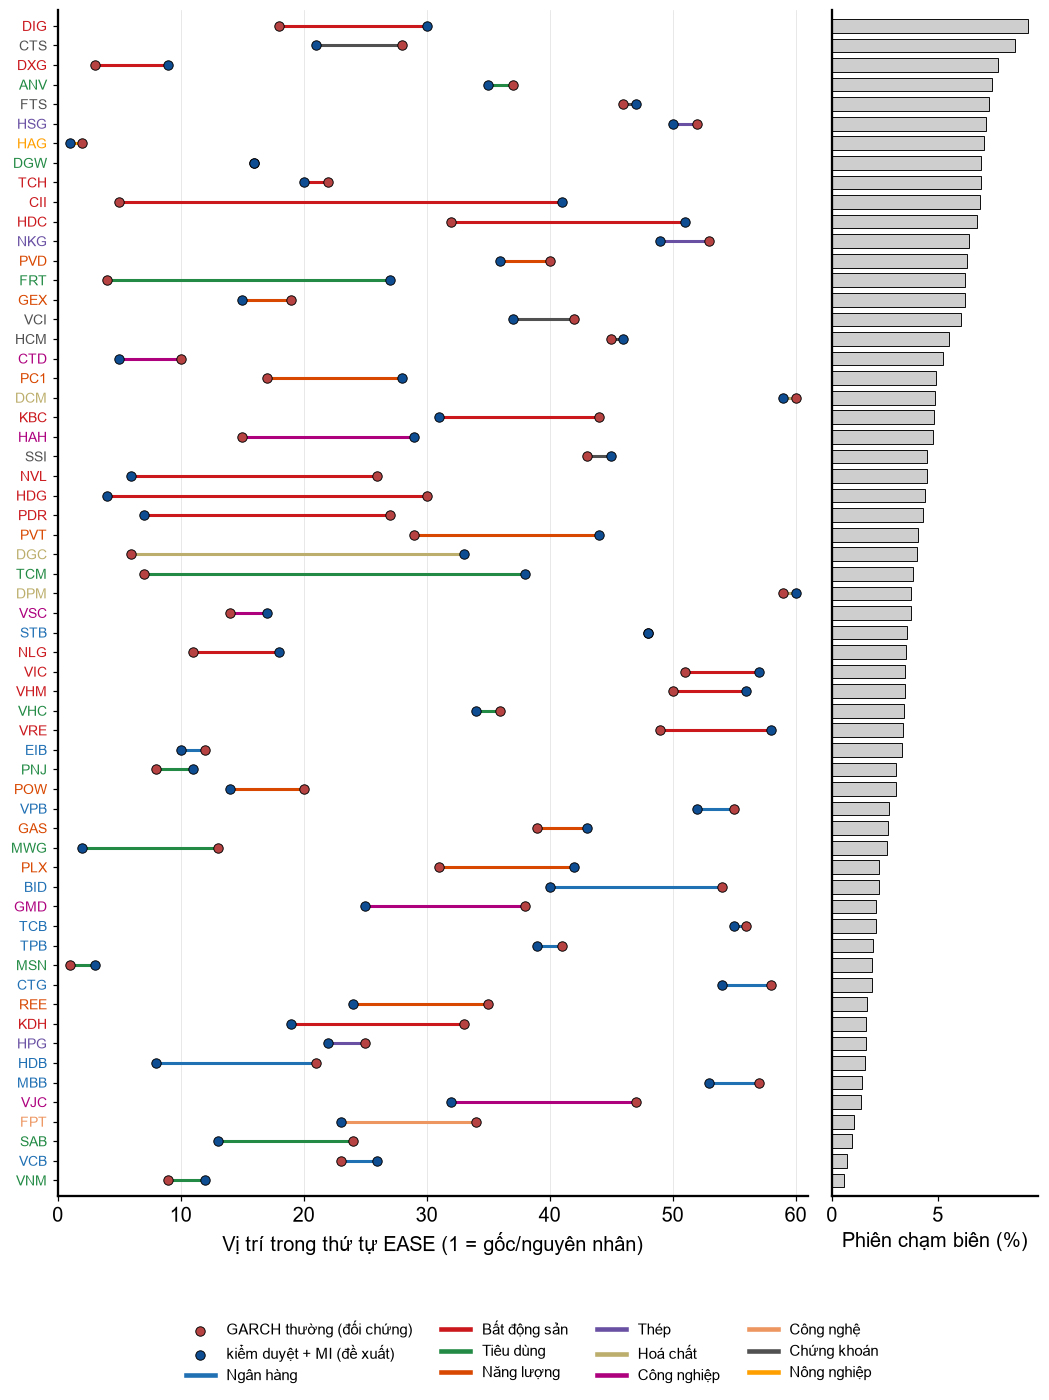

In [12]:
pos = lambda o: pd.Series({s: i + 1 for i, s in enumerate(o)})[SYMBOLS]
pos_mi_each = pd.DataFrame([pos(o) for o in o_mi["orders"]])
tab = pd.DataFrame({"ngành": pd.Series(U.SECTOR)[SYMBOLS], "chạm biên (%)": HIT.hit_pct,
                    "vị trí thường": pos(o_naive["order"]), "vị trí kiểm duyệt (điểm)": pos(o_point["order"]),
                    "vị trí MI": pos(o_mi["order"]), "vị trí MI lần 2": pos(o_mi2["order"]),
                    "vị trí MI TB (20 bản)": pos_mi_each.mean(), "vị trí MI SD (20 bản)": pos_mi_each.std()})
tab["dịch chuyển (MI − thường)"] = tab["vị trí MI"] - tab["vị trí thường"]
tab["dịch chuyển (MI lần 2 − MI)"] = tab["vị trí MI lần 2"] - tab["vị trí MI"]
U.save_table(tab.sort_values("chạm biên (%)", ascending=False), "05_ease_orders", FOLDER)
shift = tab["dịch chuyển (MI − thường)"]
print(f"|dịch chuyển| trung bình {shift.abs().mean():.1f} bậc, trung vị {shift.abs().median():.0f}, lớn nhất {shift.abs().max():.0f} ({shift.abs().idxmax()}); "
      f"nhiễu MI (|MI lần 2 − MI|) trung bình {tab['dịch chuyển (MI lần 2 − MI)'].abs().mean():.1f} bậc")
print(f"Spearman(dịch chuyển, chạm biên) = {stats.spearmanr(shift, tab['chạm biên (%)'])[0]:.3f} (p = {stats.spearmanr(shift, tab['chạm biên (%)'])[1]:.3f}); "
      f"Spearman(|dịch chuyển|, chạm biên) = {stats.spearmanr(shift.abs(), tab['chạm biên (%)'])[0]:.3f}")
print(f"Spearman(vị trí thường, chạm biên) = {stats.spearmanr(tab['vị trí thường'], tab['chạm biên (%)'])[0]:.3f}; "
      f"Spearman(vị trí MI, chạm biên) = {stats.spearmanr(tab['vị trí MI'], tab['chạm biên (%)'])[0]:.3f}")
print("Vị trí MI: SD qua 20 bản trung bình", round(tab["vị trí MI SD (20 bản)"].mean(), 2), "bậc")
print("Top 8 dịch chuyển:"); display(tab.reindex(shift.abs().sort_values(ascending=False).index).head(8).round(2))

# Hình 5: dumbbell vị trí EASE thường → MI, sắp theo tỷ lệ chạm biên
srt = tab.sort_values("chạm biên (%)", ascending=True)       # mã bị chặn nhiều nhất ở trên cùng
y = np.arange(len(srt))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 14), sharey=True, gridspec_kw={"width_ratios": [4, 1.1], "wspace": 0.05})
for yi, (s, row) in zip(y, srt.iterrows()):
    a1.plot([row["vị trí thường"], row["vị trí MI"]], [yi, yi], color=U.SECTOR_COLORS[row["ngành"]], lw=2.0, zorder=1)
a1.scatter(srt["vị trí thường"], y, s=38, color=PAL["red_strong"], edgecolor="black", linewidth=0.6, zorder=3, label="GARCH thường (đối chứng)")
a1.scatter(srt["vị trí MI"], y, s=38, color=PAL["blue_main"], edgecolor="black", linewidth=0.6, zorder=4, label="kiểm duyệt + MI (đề xuất)")
a1.set_yticks(y, srt.index, fontsize=9)
for tl, s in zip(a1.get_yticklabels(), srt.index):
    tl.set_color(U.SECTOR_COLORS[U.SECTOR[s]])
a1.set_xlim(0, P + 1); a1.set_ylim(-0.8, P - 0.2)
a1.set_xlabel("Vị trí trong thứ tự EASE (1 = gốc/nguyên nhân)")
a1.grid(axis="x", color=PAL["neutral"], lw=0.5, alpha=0.6); a1.set_axisbelow(True)
a2.barh(y, srt["chạm biên (%)"], color=PAL["neutral"], edgecolor="black", linewidth=0.6, height=0.7)
a2.set_xlabel("Phiên chạm biên (%)"); a2.tick_params(axis="y", left=False)
h1, l1 = a1.get_legend_handles_labels()
sec_h = [mpl.lines.Line2D([], [], color=U.SECTOR_COLORS[sc_], lw=3) for sc_ in U.SECTORS if sc_ in set(srt["ngành"])]
sec_l = [sc_ for sc_ in U.SECTORS if sc_ in set(srt["ngành"])]
fig.legend(h1 + sec_h, l1 + sec_l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9.5)
U.finalize_figure(fig, "05_ease_order_shift", folder=FOLDER); plt.show()

### Phân tích

- Có 5197 ô (4,12%) bị điền. Thứ tự EASE (k = 14, khử 1 nhân tố PCA) thay đổi vừa phải: đồng thuận **thường vs MI = 0,794**, thường vs kiểm duyệt điểm 0,786, điểm vs MI 0,886 (0,5 là ngẫu nhiên). Nhiễu Monte Carlo của MI: hai lần MI độc lập (seed 2026, 2027) đồng thuận 0,922 (≈ 7,8% cặp đảo vị trí chỉ do ngẫu nhiên điền); MI lần 2 vs thường 0,802. Vậy thay đổi thật sự (~20% cặp) lớn gấp khoảng 2,6 lần mức nhiễu, nhưng không lớn.
- Nhóm đối chứng: trong 20 mã ít bị chặn nhất (chạm biên ≤ 2,71%) đồng thuận thường vs MI là 0,879 (nhiễu MI 0,958); trong 20 mã bị chặn nhiều nhất (≥ 4,85%) là 0,837 (nhiễu 0,905). Mức dịch chuyển trung bình |MI − thường| = 8,5 bậc (trung vị 6, lớn nhất 36: CII 5 → 41; tiếp theo TCM +31, DGC +27, HDG −26, FRT +23); nhiễu MI chỉ 3,7 bậc. Spearman(dịch chuyển, tỷ lệ chạm biên) = 0,260 (p = 0,045) nhưng Spearman(|dịch chuyển|, chạm biên) = −0,073: **mã bị chặn nhiều không dịch chuyển nhiều hơn**. **Phân rã** (tỷ lệ cặp đảo thứ tự): thường → $Z_{obs}$ của bộ lọc kiểm duyệt + δ *chưa điền* = 12,9% (13,7% riêng trong 20 mã ít bị chặn nhất; đây là tác động của việc đổi bộ lọc GARCH); $Z_{obs}$ → điểm (thay các phiên chạm biên bằng kỳ vọng có điều kiện) = 17,4%; điểm → MI = 11,4%; tổng thường → MI = 20,6% (tỷ lệ đảo không cộng được với nhau). Nhiễu Monte Carlo của MI là 7,8%. Như vậy khoảng 13% cặp đổi chỉ do bộ lọc, không do việc điền.
- Mỗi lần điền riêng lẻ khá nhiễu: SD vị trí của một mã qua 20 bản trung bình 10,8 bậc và đồng thuận từng bản với thứ tự gộp chỉ 0,769 — thấp hơn đồng thuận thường vs MI (0,794). Chỉ khi gộp $\hat\Psi$ qua 20 bản mới ổn định (0,922 giữa hai lần gộp).
- Không có sự thật nền ở dữ liệu thật, nên không thể nói thứ tự nào đúng hơn; kết hợp với mục 3 (không cải thiện SID nhất quán), thay đổi này nên coi là **phân tích độ nhạy**, chưa phải sửa lỗi.

## 5. Kết luận

**CAcF bổ sung được gì.** (i) Mô hình động hợp lý cho xác suất chạm sàn của mã lỗ nhất: Brier ngoài mẫu 0,134 so với 0,158 (hằng số) và 0,148 (AcF), skill 14,8%, hiệu chuẩn tốt ($\bar{\hat P}$ = 0,184 so với thực 0,196). (ii) Cơ chế định lượng: sau phiên bị chặn $\alpha_t$ giảm ≈ 2,2 lần mạnh hơn phiên thường ($\hat\gamma_2^*=0{,}038$), $\sigma_t$ không phản ứng thêm ($\hat\beta_2^*\approx0$); LR cho $\beta_2^*=\gamma_2^*=0$ là 34,05, p = 4,0·10⁻⁸. $\hat P_t$ là proxy theo ngưỡng cố định $M$ nhưng kết quả không nhạy với $M$ (Brier 0,134–0,135). (iii) Bỏ kiểm duyệt đẩy Fréchet về dạng gần Gumbel (AcF: $\hat\mu$ trôi tới −59,7%, $\hat\alpha\approx21$–62, trong khi CAcF cho $\hat\alpha_t$ trung vị 5,6). (iv) GARCH kiểm duyệt cho thấy $\hat\nu$ giảm ở 60/60 mã (trung vị 4,31 → 2,98), mạnh nhất ở các mã chạm biên nhiều (DXG 8,12 → 2,79).

**CAcF không làm được gì.** Mức $\mu,\alpha$ của $Q_t$ HOSE không giải thích như chỉ số đuôi Fréchet ($\hat\mu\approx-6\%$, $Q_t$ trung vị 3,7%, $\sigma_t$ và $\alpha_t$ cùng một nhân tố động: tương quan với $\hat P_t$ 0,98); EVaR không kiểm duyệt phi thực tế (trung bình 26,8%, cực đại 389%). GARCH kiểm duyệt có $\hat a+\hat b\approx1$ ở phần lớn mã (48–54/60 mã > 0,999) và $\hat\nu\approx3$. Quan trọng nhất: **mô phỏng không cho thấy cải thiện SID nhất quán** (hiệu có lợi tối đa ≈ 2 SE ở một ô trên sáu, 40–95% lần lặp trùng nhau, và kd+MI tệ hơn thường ở α=3, hit 5%), và trên dữ liệu thật thứ tự EASE đổi cỡ 20% số cặp (đồng thuận 0,794, nhiễu MC 0,922; riêng đổi bộ lọc GARCH đã gây ≈ 13% cặp đảo) mà không tập trung ở mã bị chặn nhiều.

**Bước tiếp theo.** (1) Mô phỏng thật hơn để có độ phân giải: $p$ lớn hơn (ở α=1,5 SID gần 0 nên khó phân biệt phương pháp), có GARCH riêng từng mã và cú sốc dồn phiên (`spill=True`), $m$ điền lớn hơn. (2) Thay GARCH(1,1)–t bằng đặc tả cho phép $a+b<1$ (hoặc GJR/biến động thực hiện) trước khi dùng $z$ kiểm duyệt cho EASE. (3) Nếu dùng CAcF cho cảnh báo rủi ro, chỉ dùng $\hat P_t$ và EVaR kiểm duyệt (dưới biên), không dùng EVaR không kiểm duyệt. (4) Nếu đưa vào kết luận chính của đồ án, trình bày thứ tự MI như phân tích độ nhạy, không thay thế kết quả gốc.

In [13]:
print(f"Tổng thời gian chạy notebook: {(time.time() - T_START) / 60:.1f} phút")

Tổng thời gian chạy notebook: 1.9 phút
